<div dir="rtl" style="direction: rtl; text-align: right;">

# جلسه ۱ — مبانی پایتون

این کلاس سه جلسه است. دو جلسه‌ی اول فقط **پایتون** است و جلسه‌ی سوم سراغ **PyTorch و CNN** می‌رویم.

هدف این دو جلسه‌ی پایتون این است که وقتی جلسه‌ی سوم به کد PyTorch رسیدیم، **هیچ خطش برایتان عجیب نباشد**. پس پایتون را از دید کسی یاد می‌گیریم که قرار است با آن شبکه‌ی عصبی بنویسد.

</div>

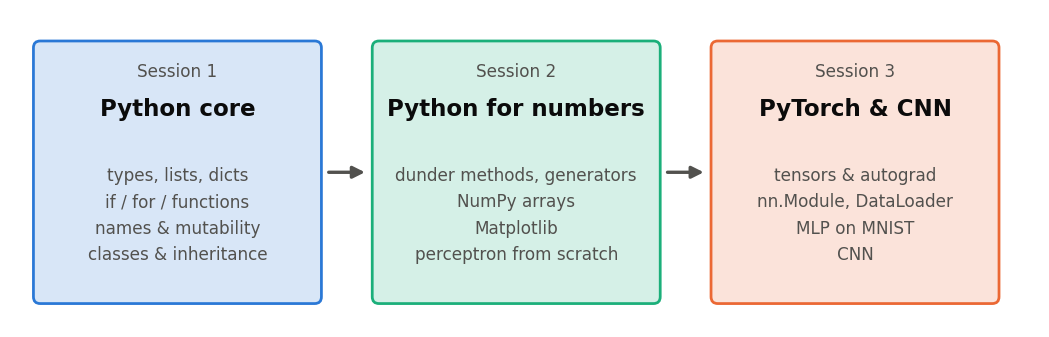

<div dir="rtl" style="direction: rtl; text-align: right;">

### برنامه‌ی امروز

| بخش | موضوع |
|---|---|
| ۰ | آشنایی با Jupyter |
| ۱ | عدد، رشته، bool و تبدیل نوع |
| ۲ | ظرف‌ها: list، tuple، dict، set |
| ۳ | شرط و حلقه |
| ۴ | comprehension |
| ۵ | تابع |
| ۶ | متغیر در پایتون «اسم» است (mutable و immutable) |
| ۷ | خطاها و `try` |
| ۸ | شیءگرایی: کلاس، شیء، ارث‌بری |
| ۹ | ماژول و `import` |

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

### مقصد: این کد

این یک حلقه‌ی آموزش معمولی در PyTorch است. الان لازم نیست بفهمیدش؛ فقط نگاهش کنید. آخر جلسه‌ی ۳ برمی‌گردیم و می‌بینیم هر خطش را می‌شناسید.

</div>

```python
class Net(nn.Module):                     # class + inheritance         (session 1)
    def __init__(self):
        super().__init__()                # why is this line required?  (session 1)
        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        return self.fc2(torch.relu(self.fc1(x)))

model = Net()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)   # generator      (session 2)

for epoch in range(5):
    for x, y in loader:                   # iterator + unpacking        (sessions 1, 2)
        logits = model(x)                 # why model(x)?               (session 2)
        loss = loss_fn(logits, y)
        optimizer.zero_grad()             # in-place change             (session 1)
        loss.backward()
        optimizer.step()

with torch.no_grad():                     # context manager             (session 2)
    acc = (model(x_test).argmax(dim=1) == y_test).float().mean()   # axis, broadcasting (session 2)
```

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۰ — آشنایی با Jupyter

نوت‌بوک از **سلول** ساخته شده. دو نوع سلول داریم:

- **سلول کد** ← کد پایتون. با `Shift + Enter` اجرا می‌شود و خروجی زیرش می‌آید.
- **سلول متن (Markdown)** ← همین متنی که دارید می‌خوانید.

چند نکته:

- **مقدار آخرین خط** هر سلول خودکار نمایش داده می‌شود (حتی بدون `print`).
- متغیرهایی که در یک سلول می‌سازید در سلول‌های بعدی هم هستند. ترتیب **اجرا** مهم است، نه ترتیب روی صفحه.
- اگر کار عجیبی رخ داد: منوی Kernel ← Restart و همه‌ی سلول‌ها را از اول اجرا کنید.
- `help(چیزی)` یا `چیزی?` توضیحات آن را نشان می‌دهد.

</div>

In [1]:
print("Hello, deep learning!")
2 + 3          # the value of the last line is shown automatically

Hello, deep learning!


5

In [2]:
help(len)

Help on built-in function len in module builtins:

len(obj, /)
    Return the number of items in a container.



<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۱ — عدد، رشته، bool

### متغیر و نوع

در پایتون لازم نیست نوع متغیر را اعلام کنید. فقط مقدار بدهید؛ پایتون خودش نوع را می‌فهمد. با `type()` می‌توانید نوع هر چیزی را ببینید.

</div>

In [3]:
epochs = 10            # int   (integer)
lr = 0.001             # float (real number)
name = "mnist"         # str   (string / text)
use_gpu = True         # bool  (True / False)
best_model = None      # None  ("nothing yet")

print(type(epochs), type(lr), type(name), type(use_gpu), type(best_model))

<class 'int'> <class 'float'> <class 'str'> <class 'bool'> <class 'NoneType'>


<div dir="rtl" style="direction: rtl; text-align: right;">

### عملگرهای ریاضی

| عملگر | معنی | مثال | نتیجه |
|---|---|---|---|
| `+ - *` | جمع، تفریق، ضرب | `7 * 2` | `14` |
| `/` | تقسیم (همیشه float) | `7 / 2` | `3.5` |
| `//` | تقسیم صحیح | `7 // 2` | `3` |
| `%` | باقی‌مانده | `7 % 2` | `1` |
| `**` | توان | `2 ** 10` | `1024` |

**مثال واقعی:** ۶۰۰۰۰ تصویر داریم و هر batch ۱۲۸ تاست. چند batch کامل داریم و چند تصویر اضافه می‌ماند؟

</div>

In [4]:
n_images, batch_size = 60000, 128

print(n_images / batch_size)     # float division
print(n_images // batch_size)    # full batches
print(n_images % batch_size)     # images left for the last (smaller) batch
print(2 ** 10, 1e-3)             # power, scientific notation (1e-3 == 0.001)

468.75
468
96
1024 0.001


In [ ]:
# Shorthand update operators
step = 0
step += 1       # same as step = step + 1
step *= 10
print(step)

<div dir="rtl" style="direction: rtl; text-align: right;">

### رشته (str) و f-string

رشته را با `'...'` یا `"..."` می‌سازیم. مهم‌ترین ابزار رشته در کد دیپ لرنینگ **f-string** است: یک `f` قبل از رشته بگذارید و هر متغیری را داخل `{}` بنویسید.

بعد از `:` می‌توانید قالب را مشخص کنید: `{x:.3f}` یعنی ۳ رقم اعشار، `{x:.2%}` یعنی درصد، `{x:03d}` یعنی عدد صحیح سه‌رقمی با صفر در اول.

</div>

In [5]:
epoch, loss, acc = 3, 0.123456, 0.9731

print("epoch", epoch, "loss", loss)                       # plain print
print(f"epoch {epoch:03d} | loss {loss:.3f} | acc {acc:.2%}")   # f-string

epoch 3 loss 0.123456
epoch 003 | loss 0.123 | acc 97.31%


In [6]:
s = "conv1.weight"
print(len(s))                 # number of characters
print(s.upper())
print(s.split("."))           # split into a list
print(s.replace("conv", "layer"))
print(s.startswith("conv"), "weight" in s)
print("-".join(["a", "b", "c"]))

12
CONV1.WEIGHT
['conv1', 'weight']
layer1.weight
True True
a-b-c


<div dir="rtl" style="direction: rtl; text-align: right;">

### bool و مقایسه

مقایسه‌ها (`==`، `!=`، `<`، `>`، `<=`، `>=`) یک `bool` برمی‌گردانند. برای ترکیبشان از `and`، `or` و `not` استفاده می‌کنیم (نه `&&` و `||` مثل C).

</div>

In [ ]:
acc = 0.97
print(acc > 0.95)
print(acc > 0.95 and acc < 0.99)
print(0.95 < acc < 0.99)          # Python allows chained comparisons
print(not True)
print(True + True)                # True behaves like 1 -> handy for counting

<div dir="rtl" style="direction: rtl; text-align: right;">

### تبدیل نوع

`int()`، `float()`، `str()`، `bool()` نوع را عوض می‌کنند.

</div>

In [ ]:
print(int("42") + 1)
print(float("3.5") * 2)
print("accuracy: " + str(97))
print(int(3.99))                  # truncates, does not round
print(round(3.99), round(3.14159, 2))

<div dir="rtl" style="direction: rtl; text-align: right;">

**خودتان امتحان کنید:** متغیرهای `train_loss = 0.4567` و `val_loss = 0.5123` را بسازید و با یک f-string چاپ کنید:
`train 0.457 | val 0.512 | gap 0.056`

</div>

In [12]:
# your code here


<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۲ — ظرف‌ها

چهار ظرف اصلی پایتون:

| ظرف | سینتکس | ترتیب دارد؟ | قابل تغییر؟ | کاربرد |
|---|---|---|---|---|
| `list` | `[1, 2, 3]` | بله | بله | دنباله‌ای از چیزها (لاس هر epoch) |
| `tuple` | `(1, 2, 3)` | بله | خیر | چند مقدار ثابت با هم (shape تصویر) |
| `dict` | `{"lr": 0.1}` | — | بله | کلید ← مقدار (تنظیمات مدل) |
| `set` | `{1, 2, 3}` | خیر | بله | عناصر یکتا (کلاس‌های موجود) |

### list

اندیس‌ها از **صفر** شروع می‌شوند (نه از ۱ مثل متلب). اندیس منفی از ته می‌شمارد.

</div>

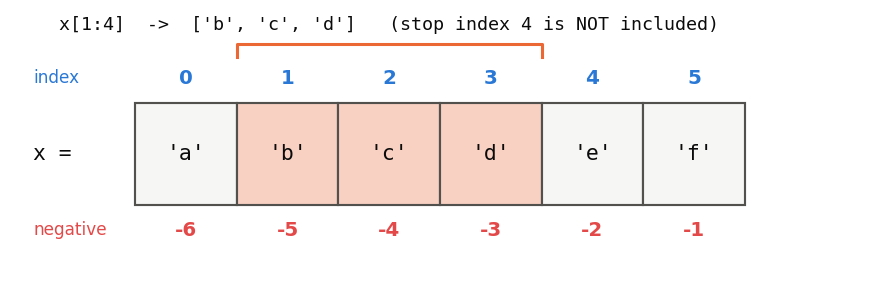

In [13]:
x = ["a", "b", "c", "d", "e", "f"]

print(x[0], x[-1])        # first, last
print(x[1:4])             # slice [start:stop]  -> stop is NOT included
print(x[:3], x[3:])       # from the start / to the end
print(x[::2])             # [start:stop:step] -> every second item
print(x[::-1])            # reversed

a f
['b', 'c', 'd']
['a', 'b', 'c'] ['d', 'e', 'f']
['a', 'c', 'e']
['f', 'e', 'd', 'c', 'b', 'a']


In [ ]:
losses = [0.9, 0.7]
losses.append(0.5)            # add one item at the end
losses.extend([0.4, 0.35])    # add many items
print(losses, len(losses))

losses[0] = 1.0               # lists can be changed
last = losses.pop()           # remove and return the last item
print(losses, last)

print(min(losses), max(losses), sum(losses) / len(losses))
print(sorted([3, 1, 2]), 0.5 in losses)

<div dir="rtl" style="direction: rtl; text-align: right;">

### tuple و unpacking

tuple مثل list است ولی **تغییرناپذیر**. معمولاً وقتی چند مقدار «با هم یک چیز» را می‌سازند از آن استفاده می‌کنیم؛ مثلاً shape یک تصویر.

**unpacking** یعنی باز کردن یک tuple (یا list) در چند متغیر. این را در هر حلقه‌ی آموزش می‌بینید: `for x, y in loader`.

</div>

In [ ]:
shape = (28, 28)
h, w = shape                  # unpacking
print(h, w)

a, b = 1, 2
a, b = b, a                   # swap in one line
print(a, b)

first, *rest = [10, 20, 30, 40]
print(first, rest)

<div dir="rtl" style="direction: rtl; text-align: right;">

### dict

dict یک جدول «کلید ← مقدار» است. تنظیمات آموزش (hyper-parameterها) معمولاً در یک dict نگه داشته می‌شوند. در PyTorch وزن‌های مدل هم یک dict هستند (`state_dict`).

</div>

In [ ]:
config = {"lr": 0.01, "epochs": 5, "batch_size": 64}

print(config["lr"])
config["momentum"] = 0.9                 # add a new key
config["epochs"] = 10                    # change a value
print(config)

print(config.get("dropout", 0.0))        # .get -> default value if the key is missing
print("lr" in config)

for key, value in config.items():        # walk over (key, value) pairs
    print(f"{key:>10} = {value}")

In [ ]:
# a common pattern: collect a history of metrics during training
history = {"loss": [], "acc": []}
history["loss"].append(0.8)
history["acc"].append(0.71)
history["loss"].append(0.5)
history["acc"].append(0.85)
print(history)

In [ ]:
# set: unique items only
labels = [3, 1, 3, 0, 1, 1, 2]
print(set(labels), len(set(labels)), "classes")

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۳ — شرط و حلقه

### تورفتگی (indentation)

در پایتون `{}` یا `end` نداریم. **تورفتگی** (معمولاً ۴ فاصله) مشخص می‌کند کدام خط‌ها داخل `if` یا حلقه یا تابع هستند. بعد از `if`، `for`، `def` و `class` حتماً `:` بگذارید.

</div>

In [ ]:
acc = 0.83

if acc > 0.9:
    print("great")
elif acc > 0.8:
    print("good")          # this line is inside the elif
else:
    print("keep training")
print("done")              # this line is outside: always runs

<div dir="rtl" style="direction: rtl; text-align: right;">

### حلقه‌ی `for`

حلقه‌ی `for` در پایتون روی **عناصر** یک دنباله می‌چرخد، نه روی شمارنده. اگر شمارنده لازم دارید از `range` استفاده کنید.

- `range(5)` ← `0, 1, 2, 3, 4`
- `range(2, 10, 3)` ← `2, 5, 8`

</div>

In [ ]:
for epoch in range(3):
    print("epoch", epoch)

for name in ["conv1", "conv2", "fc"]:
    print("layer:", name)

<div dir="rtl" style="direction: rtl; text-align: right;">

### `enumerate` و `zip`

- `enumerate(seq)` ← هم **اندیس** را می‌دهد هم **عنصر** را.
- `zip(a, b)` ← روی دو دنباله **هم‌زمان** راه می‌رود.

هر دو جفت (tuple) می‌دهند، پس با unpacking می‌گیریمشان.

</div>

In [ ]:
names = ["conv1", "conv2", "fc"]
sizes = [16, 32, 10]

for i, name in enumerate(names):
    print(i, name)

for name, size in zip(names, sizes):
    print(f"{name} -> {size}")

<div dir="rtl" style="direction: rtl; text-align: right;">

### `while`، `break`، `continue`

- `while شرط:` ← تا وقتی شرط درست است تکرار کن.
- `break` ← همین الان از حلقه بیرون برو.
- `continue` ← بقیه‌ی این دور را رد کن و برو دور بعد.

**مثال: early stopping.** اگر loss اعتبارسنجی ۲ epoch پشت سر هم بهتر نشد، آموزش را متوقف کن.

</div>

In [ ]:
val_losses = [0.90, 0.70, 0.60, 0.62, 0.61, 0.65, 0.50]

best, patience, bad_epochs = float("inf"), 2, 0
for epoch, loss in enumerate(val_losses):
    if loss < best:
        best, bad_epochs = loss, 0
        print(f"epoch {epoch}: {loss:.2f}  new best")
    else:
        bad_epochs += 1
        print(f"epoch {epoch}: {loss:.2f}  no improvement ({bad_epochs})")
        if bad_epochs == patience:
            print("early stopping!")
            break

<div dir="rtl" style="direction: rtl; text-align: right;">

**خودتان امتحان کنید:** با یک حلقه روی لیست `losses = [0.9, 0.75, 0.6, 0.52, 0.47]`، برای هر epoch مقدار بهبود نسبت به epoch قبل را چاپ کنید (برای epoch اول چیزی چاپ نکنید). راهنمایی: `zip(losses, losses[1:])`.

</div>

In [ ]:
losses = [0.9, 0.75, 0.6, 0.52, 0.47]
# your code here

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۴ — comprehension

ساختن یک لیست از روی یک دنباله‌ی دیگر، در یک خط. الگو:

`[عبارت for عنصر in دنباله if شرط]`

خیلی در کد پایتونی دیده می‌شود، پس باید بتوانید بخوانیدش.

</div>

In [ ]:
# the long way
squares = []
for i in range(6):
    squares.append(i ** 2)
print(squares)

# the comprehension way: same result
squares = [i ** 2 for i in range(6)]
evens = [i for i in range(10) if i % 2 == 0]
print(squares, evens)

In [14]:
# dict comprehension: very common for label maps
classes = ["cat", "dog", "bird"]
class_to_idx = {name: i for i, name in enumerate(classes)}
print(class_to_idx)

# layer sizes -> (in, out) pairs of every layer
sizes = [784, 256, 64, 10]
pairs = [(sizes[i], sizes[i + 1]) for i in range(len(sizes) - 1)]
print(pairs)

{'cat': 0, 'dog': 1, 'bird': 2}
[(784, 256), (256, 64), (64, 10)]


<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۵ — تابع

تابع یک تکه کد با اسم است که ورودی می‌گیرد و خروجی برمی‌گرداند. هر کاری که بیش از یک بار تکرار می‌شود باید تابع شود.

</div>

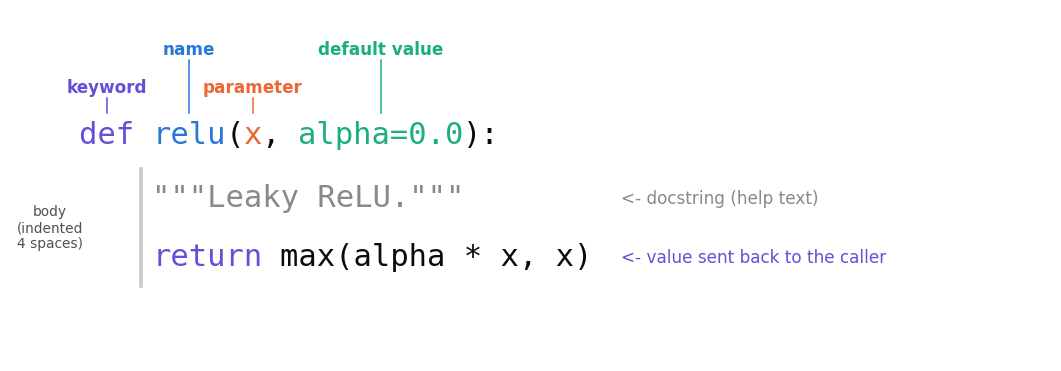

In [ ]:
def relu(x, alpha=0.0):
    """Leaky ReLU: x if x > 0, else alpha * x."""
    return max(alpha * x, x)

print(relu(3.0))
print(relu(-2.0))
print(relu(-2.0, alpha=0.1))     # override the default value
help(relu)                       # the docstring shows up here

<div dir="rtl" style="direction: rtl; text-align: right;">

### آرگومان موقعیتی و نام‌دار

می‌توانید آرگومان‌ها را به ترتیب بدهید یا با اسم. با اسم خواناتر است و ترتیب مهم نیست. این شکل را در PyTorch زیاد می‌بینید: `nn.Conv2d(1, 16, kernel_size=3, padding=1)`.

</div>

In [ ]:
def conv_output_size(size, kernel, stride=1, padding=0):
    return (size + 2 * padding - kernel) // stride + 1

print(conv_output_size(28, 3))                         # positional
print(conv_output_size(28, 3, padding=1))              # keep the size
print(conv_output_size(size=28, kernel=2, stride=2))   # all by name

<div dir="rtl" style="direction: rtl; text-align: right;">

### برگرداندن چند مقدار

`return a, b` در واقع یک tuple برمی‌گرداند که با unpacking باز می‌کنیم.

</div>

In [ ]:
def mean_std(values):
    n = len(values)
    mean = sum(values) / n
    std = (sum((v - mean) ** 2 for v in values) / n) ** 0.5
    return mean, std

m, s = mean_std([2, 4, 4, 4, 5, 5, 7, 9])
print(m, s)

<div dir="rtl" style="direction: rtl; text-align: right;">

### محدوده‌ی متغیر (scope)

متغیری که **داخل** تابع ساخته می‌شود فقط داخل همان تابع وجود دارد.

</div>

In [ ]:
def f():
    inside = 123
    return inside

f()
try:
    print(inside)
except NameError as e:
    print("NameError:", e)

<div dir="rtl" style="direction: rtl; text-align: right;">

### `*args` و `**kwargs`

- `*args` ← هر تعداد آرگومان موقعیتی را در یک **tuple** جمع می‌کند.
- `**kwargs` ← هر تعداد آرگومان نام‌دار را در یک **dict** جمع می‌کند.
- موقع **صدا زدن**، `*` و `**` برعکس عمل می‌کنند: باز می‌کنند. مثلاً `f(**config)` کلیدهای dict را به‌عنوان آرگومان نام‌دار می‌فرستد.

</div>

In [ ]:
def show(*args, **kwargs):
    print("args  :", args)
    print("kwargs:", kwargs)

show(1, 2, 3, lr=0.01, momentum=0.9)

In [ ]:
def make_optimizer(lr, momentum=0.0, weight_decay=0.0):
    return f"SGD(lr={lr}, momentum={momentum}, weight_decay={weight_decay})"

config = {"lr": 0.1, "momentum": 0.9}
print(make_optimizer(**config))          # same as make_optimizer(lr=0.1, momentum=0.9)

<div dir="rtl" style="direction: rtl; text-align: right;">

### تابع هم یک «شیء» است

تابع را می‌شود در متغیر گذاشت، در لیست و dict ریخت و به تابع دیگر پاس داد. برای همین می‌توانیم تابع فعال‌سازی را مثل یک پارامتر به یک نورون بدهیم.

`lambda` یک تابع کوچک یک‌خطی و بی‌نام است.

</div>

In [15]:
def identity(x):
    return x

def neuron(x, w, b, activation):
    return activation(w * x + b)          # the function arrives as an argument

print(neuron(2.0, w=-1.5, b=1.0, activation=relu))
print(neuron(2.0, w=-1.5, b=1.0, activation=identity))

activations = {"relu": relu, "linear": identity, "square": lambda x: x ** 2}
print(activations["square"](3))

NameError: name 'relu' is not defined

<div dir="rtl" style="direction: rtl; text-align: right;">

**خودتان امتحان کنید:** تابعی به اسم `accuracy(preds, labels)` بنویسید که دو لیست هم‌اندازه بگیرد و درصد عناصر برابر را برگرداند. `accuracy([1, 0, 2, 2], [1, 1, 2, 0])` باید `0.5` بدهد. (راهنمایی: `zip` و اینکه `True` مثل ۱ جمع می‌شود.)

</div>

In [ ]:
def accuracy(preds, labels):
    # your code here
    pass

print(accuracy([1, 0, 2, 2], [1, 1, 2, 0]))

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۶ — متغیر در پایتون «جعبه» نیست، «اسم» است

مهم‌ترین نکته‌ی این جلسه، و ریشه‌ی نصف باگ‌های عجیب در کد دیپ لرنینگ.

در C یا متلب، متغیر مثل یک **جعبه** است که مقدار داخلش می‌نشیند و `b = a` محتوا را کپی می‌کند. در پایتون:

- **شیء (object)** جایی در حافظه ساخته می‌شود.
- **متغیر** فقط یک **برچسب** است که به آن شیء چسبیده.
- `b = a` چیزی را کپی نمی‌کند؛ فقط یک برچسب دوم روی **همان** شیء می‌زند.

</div>

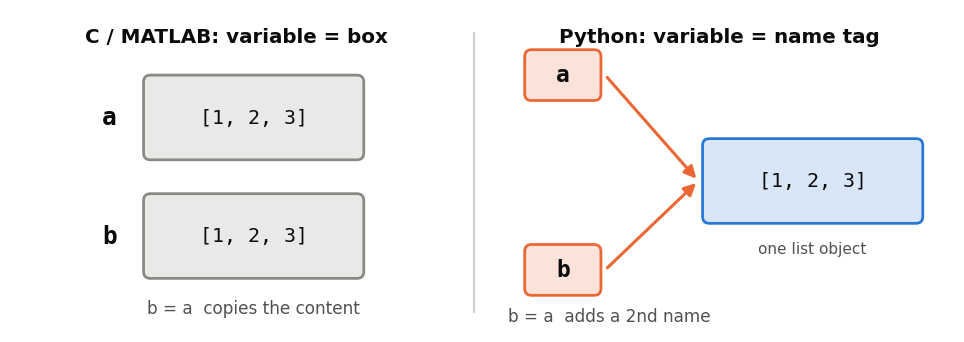

In [ ]:
a = [1, 2, 3]
b = a            # no copy! b is a second name for the SAME list
b.append(4)

print("a =", a)  # a changed too
print("b =", b)

<div dir="rtl" style="direction: rtl; text-align: right;">

`id()` آدرس شیء را می‌دهد. `is` می‌پرسد «آیا **همان** شیء است؟» و `==` می‌پرسد «آیا مقدارشان برابر است؟».

</div>

In [ ]:
print(id(a), id(b))
print("a is b:", a is b)

c = [1, 2, 3, 4]              # a different object with equal content
print("a == c:", a == c)
print("a is c:", a is c)

<div dir="rtl" style="direction: rtl; text-align: right;">

### mutable و immutable

بعضی اشیا بعد از ساخته‌شدن **قابل تغییرند** (mutable) و بعضی **نیستند** (immutable).

| immutable (تغییرناپذیر) | mutable (تغییرپذیر) |
|---|---|
| `int`، `float`، `bool`، `str`، `tuple` | `list`، `dict`، `set` |
| | آرایه‌ی NumPy، تنسور PyTorch، مدل‌ها |

با اشیای immutable هیچ‌وقت غافلگیر نمی‌شوید، چون هر «تغییر» در واقع یک شیء **جدید** می‌سازد:

</div>

In [ ]:
x = 10
y = x
y += 1           # int is immutable -> y now points to a NEW object (11)
print(x, y)      # x is untouched

t = (1, 2, 3)
try:
    t[0] = 99
except TypeError as e:
    print("TypeError:", e)

<div dir="rtl" style="direction: rtl; text-align: right;">

### تله‌ی معروف: `a += ...` با `a = a + ...` یکی نیست

- `a = a + [3]` یک لیست **جدید** می‌سازد و برچسب `a` را روی آن می‌گذارد.
- `a += [3]` همان لیست قبلی را **درجا (in-place)** تغییر می‌دهد.

</div>

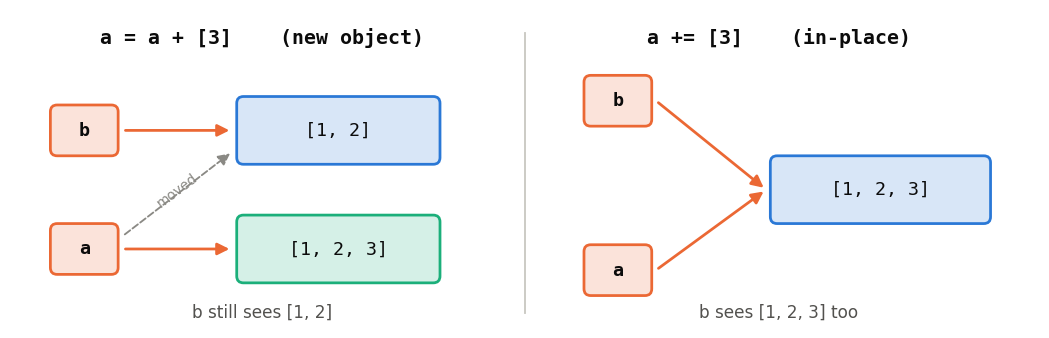

In [ ]:
a = [1, 2]
b = a
a = a + [3]      # new object
print("a = a + [3]  ->  a:", a, "| b:", b)

a = [1, 2]
b = a
a += [3]         # in-place
print("a += [3]     ->  a:", a, "| b:", b)

<div dir="rtl" style="direction: rtl; text-align: right;">

**چرا برای دیپ لرنینگ مهم است؟** در جلسه‌ی ۳ وزن‌ها را این‌طور آپدیت می‌کنیم: `w -= lr * grad`. اگر بنویسید `w = w - lr * grad` یک تنسور **جدید** ساخته می‌شود و اسم `w` دیگر به وزن اصلی مدل اشاره نمی‌کند.

### پاس‌دادن به تابع

آرگومان تابع فقط **یک اسم جدید روی همان شیء** است:

- اگر داخل تابع شیء را **تغییر** بدهید (مثل `append`) ← بیرون هم دیده می‌شود.
- اگر داخل تابع اسم را به شیء دیگری **وصل** کنید (با `=`) ← بیرون هیچ اتفاقی نمی‌افتد.

برای همین است که `optimizer.step()` بدون اینکه چیزی برگرداند، وزن‌های مدل شما را عوض می‌کند.

</div>

In [ ]:
def mutate(lst):
    lst.append(99)       # changes the object the caller also sees

def rebind(lst):
    lst = [0, 0, 0]      # only the local name moves to a new object

data = [1, 2, 3]
mutate(data)
print("after mutate:", data)

rebind(data)
print("after rebind:", data)

In [ ]:
# Classic trap: a mutable default argument is created ONCE, not on every call
def add_loss(value, history=[]):
    history.append(value)
    return history

print(add_loss(0.9))
print(add_loss(0.5))     # surprise: the old value is still there!

# The correct pattern
def add_loss(value, history=None):
    if history is None:
        history = []
    history.append(value)
    return history

print(add_loss(0.9), add_loss(0.5))

<div dir="rtl" style="direction: rtl; text-align: right;">

### کپی واقعی: shallow و deep

وقتی واقعاً یک نسخه‌ی مستقل می‌خواهید:

- `copy.copy(x)` یا `x.copy()` ← **کپی سطحی**: ظرف بیرونی جدید است ولی اشیای داخلش مشترک‌اند.
- `copy.deepcopy(x)` ← **کپی عمیق**: همه‌چیز تا ته مستقل می‌شود.

</div>

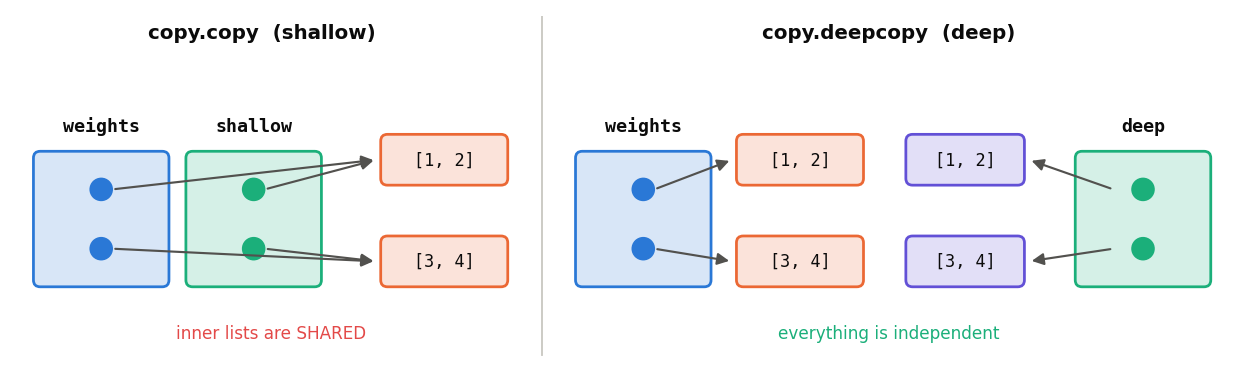

In [ ]:
import copy

weights = [[1, 2], [3, 4]]           # list of lists (think: layers)
shallow = copy.copy(weights)
deep = copy.deepcopy(weights)

weights[0][0] = 999

print("original:", weights)
print("shallow :", shallow)          # inner lists are shared -> changed
print("deep    :", deep)             # fully independent

<div dir="rtl" style="direction: rtl; text-align: right;">

کاربرد واقعی: ذخیره‌ی بهترین مدل حین آموزش. `best = model.state_dict()` فقط یک اسم دیگر روی همان وزن‌هاست و با ادامه‌ی آموزش `best` هم عوض می‌شود. درستش: `best = copy.deepcopy(model.state_dict())`.

</div>

In [ ]:
# Same idea, another famous trap: `*` repeats the SAME inner list
grid = [[0] * 3] * 2
grid[0][0] = 7
print(grid)                          # both rows changed

grid = [[0] * 3 for _ in range(2)]   # correct: a new list per row
grid[0][0] = 7
print(grid)

<div dir="rtl" style="direction: rtl; text-align: right;">

**جمع‌بندی بخش ۶**

1. `=` هیچ‌وقت کپی نمی‌کند، فقط اسم می‌گذارد.
2. اشیای mutable (لیست، آرایه، تنسور، مدل) را اگر از یک جا عوض کنید، از همه‌ی اسم‌ها دیده می‌شود.
3. کپی مستقل می‌خواهید؟ `copy.deepcopy` (در NumPy: `.copy()`، در PyTorch: `.clone()`).

**خودتان امتحان کنید:** بدون اجرا بگویید خروجی چیست، بعد اجرا کنید.

</div>

In [ ]:
a = [1, 2]
b = a
c = a.copy()
a.append(3)
print(b, c)

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۷ — خطاها

### خواندن پیغام خطا (traceback)

وقتی خطا می‌گیرید نترسید. **از پایین بخوانید**: خط آخر نوع خطا و توضیحش را می‌گوید، خط‌های بالاتر می‌گویند خطا از کجا آمده.

خطاهای رایج:

| خطا | یعنی |
|---|---|
| `NameError` | اسمی که تعریف نشده (یا سلولش اجرا نشده) |
| `TypeError` | عملیات روی نوع نامناسب (`"a" + 1`) |
| `IndexError` | اندیس بیرون از محدوده |
| `KeyError` | کلید در dict نیست |
| `AttributeError` | شیء چنین متد یا ویژگی‌ای ندارد |
| `ValueError` / `RuntimeError` | مقدار نامعتبر؛ در PyTorch اکثر خطاهای shape از این نوع‌اند |

اجرای سلول زیر **عمداً** خطا می‌دهد. پیغام را بخوانید:

</div>

In [16]:
config = {"lr": 0.1}
config["learning_rate"]

KeyError: 'learning_rate'

<div dir="rtl" style="direction: rtl; text-align: right;">

### `try` / `except`

اگر می‌دانید ممکن است خطایی رخ دهد و می‌خواهید برنامه ادامه پیدا کند:

</div>

In [ ]:
values = ["0.5", "abc", "0.25"]
for v in values:
    try:
        print(float(v) * 2)
    except ValueError as e:
        print("skipped:", e)

<div dir="rtl" style="direction: rtl; text-align: right;">

### `raise` و `assert`

خودتان هم می‌توانید خطا بدهید. `assert شرط, پیام` یعنی «اگر شرط غلط بود، با این پیام متوقف شو». برای چک‌کردن shape در کد دیپ لرنینگ عالی است.

</div>

In [ ]:
def check_batch(images, labels):
    assert len(images) == len(labels), f"{len(images)} images but {len(labels)} labels"
    return "ok"

print(check_batch([1, 2, 3], [0, 1, 1]))
try:
    check_batch([1, 2, 3], [0, 1])
except AssertionError as e:
    print("AssertionError:", e)

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۸ — شیءگرایی (OOP)

### چرا کلاس؟

یک نورون را در نظر بگیرید. **داده** دارد (`w` و `b`) و **رفتار** دارد (حساب کردن خروجی). اگر بخواهیم ۱۰۰ نورون داشته باشیم، نگه‌داشتن ۲۰۰ متغیر جدا و یک تابع جدا سخت و پرخطاست.

**کلاس** داده و رفتار را کنار هم بسته‌بندی می‌کند:

- **کلاس** = نقشه (blueprint).
- **شیء (instance)** = چیزی که از روی نقشه ساخته می‌شود. از یک کلاس هر تعداد شیء می‌شود ساخت، هر کدام با داده‌ی خودش.

در PyTorch **همه‌چیز کلاس است**: مدل، لایه، دیتاست، optimizer. پس این بخش قلب جلسه است.

</div>

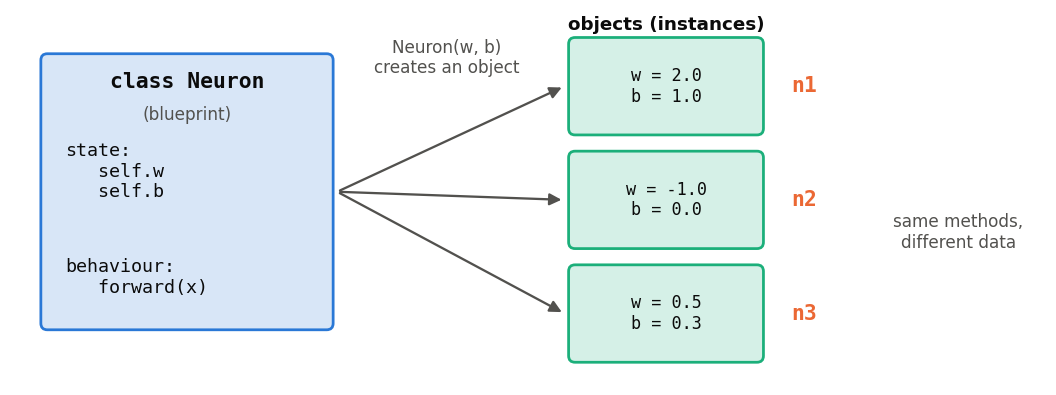

<div dir="rtl" style="direction: rtl; text-align: right;">

### اولین کلاس

- `class Neuron:` ← تعریف نقشه.
- `__init__` ← موقع **ساخت** شیء خودکار اجرا می‌شود و **حالت** (state) آن را می‌سازد. به آن سازنده (constructor) می‌گویند.
- `self` ← خودِ همان شیء. هر متد آن را به‌عنوان آرگومان اول می‌گیرد. `self.w = w` یعنی «`w` را روی این شیء ذخیره کن».
- **متد** = تابعی که داخل کلاس تعریف شده.

</div>

In [ ]:
class Neuron:
    def __init__(self, w, b):
        self.w = w               # attributes: the state lives on the object
        self.b = b

    def forward(self, x):        # a method
        return self.w * x + self.b

n1 = Neuron(w=2.0, b=1.0)        # calls __init__ behind the scenes
n2 = Neuron(w=-1.0, b=0.0)       # same blueprint, different state

print(n1.w, n2.w)
print(n1.forward(3.0), n2.forward(3.0))

<div dir="rtl" style="direction: rtl; text-align: right;">

`n1.forward(3.0)` فقط شکل خلاصه‌ی `Neuron.forward(n1, 3.0)` است. یعنی پایتون خودش شیء را به‌عنوان `self` می‌فرستد. این همان راز `self` است:

</div>

In [ ]:
print(Neuron.forward(n1, 3.0))

<div dir="rtl" style="direction: rtl; text-align: right;">

### حالت شیء تغییر می‌کند

اشیایی که خودمان می‌سازیم **mutable** هستند. یک متد می‌تواند `self.w` را تغییر بدهد؛ این دقیقاً کاری است که «یادگیری» می‌کند.

</div>

In [ ]:
class Neuron:
    def __init__(self, w, b):
        self.w = w
        self.b = b
        self.n_updates = 0

    def forward(self, x):
        return self.w * x + self.b

    def update(self, dw, db, lr=0.1):
        self.w -= lr * dw            # change the object's own state
        self.b -= lr * db
        self.n_updates += 1

    def __repr__(self):              # what print() shows (more on __xxx__ in session 2)
        return f"Neuron(w={self.w:.2f}, b={self.b:.2f}, updates={self.n_updates})"

n = Neuron(1.0, 0.0)
print(n)
n.update(dw=2.0, db=-1.0)
n.update(dw=2.0, db=-1.0)
print(n)

<div dir="rtl" style="direction: rtl; text-align: right;">

**خودتان امتحان کنید:** کلاس `AverageMeter` بنویسید که میانگین loss را حین آموزش نگه دارد (این کلاس در کدهای واقعی خیلی دیده می‌شود):

- `__init__` ← `self.total = 0` و `self.count = 0`
- `update(self, value)` ← مقدار را به جمع اضافه و شمارنده را یکی زیاد کند
- `average(self)` ← میانگین را برگرداند

</div>

In [ ]:
class AverageMeter:
    # your code here
    pass

# meter = AverageMeter()
# for loss in [0.9, 0.7, 0.5]:
#     meter.update(loss)
# print(meter.average())     # 0.7

<div dir="rtl" style="direction: rtl; text-align: right;">

### ارث‌بری (inheritance)

ارث‌بری یعنی کلاس **فرزند** همه‌ی امکانات کلاس **والد** را دارد و فقط چیزهای خودش را اضافه یا عوض می‌کند. سینتکس: `class Child(Parent):`

ایده‌ی `nn.Module` در PyTorch همین است: PyTorch یک کلاس والد نوشته که کارهای سخت (نگه‌داشتن پارامترها، انتقال به GPU، ذخیره و ...) را بلد است. شما فقط دو چیز می‌نویسید: `__init__` (چه لایه‌هایی دارم) و `forward` (داده چطور از لایه‌ها رد می‌شود).

</div>

In [ ]:
class Animal:
    def __init__(self, name):
        self.name = name

    def speak(self):
        return "..."

    def introduce(self):                       # uses speak() of whatever the object is
        return f"I am {self.name} and I say {self.speak()}"


class Dog(Animal):
    def speak(self):                           # override the parent's method
        return "woof"


class Cat(Animal):
    def __init__(self, name, lives=9):
        super().__init__(name)                 # run the parent's __init__ first
        self.lives = lives

    def speak(self):
        return "meow"


for a in [Animal("generic"), Dog("rex"), Cat("tom")]:
    print(a.introduce())
print(Cat("tom").lives, isinstance(Dog("rex"), Animal))

<div dir="rtl" style="direction: rtl; text-align: right;">

`Dog` متد `introduce` ندارد ولی از `Animal` ارث برده است. `introduce` هم `speak` را صدا می‌زند و پایتون نسخه‌ی **فرزند** را اجرا می‌کند.

`super().__init__(...)` یعنی «`__init__` والد را هم اجرا کن». اگر فرزند `__init__` خودش را بنویسد و این خط را فراموش کند، کارهایی که والد در `__init__` می‌کرد انجام نمی‌شود.

### یک `nn.Module` اسباب‌بازی

حالا با همین ایده یک نسخه‌ی کوچک از `nn.Module` می‌سازیم. یک چیز جدید اینجا هست: متد `__call__`. اگر کلاسی `__call__` داشته باشد، شیء آن را می‌شود **مثل تابع صدا زد**: `model(x)`. (جلسه‌ی ۲ مفصل درباره‌ی این متدهای `__xxx__` صحبت می‌کنیم.)

</div>

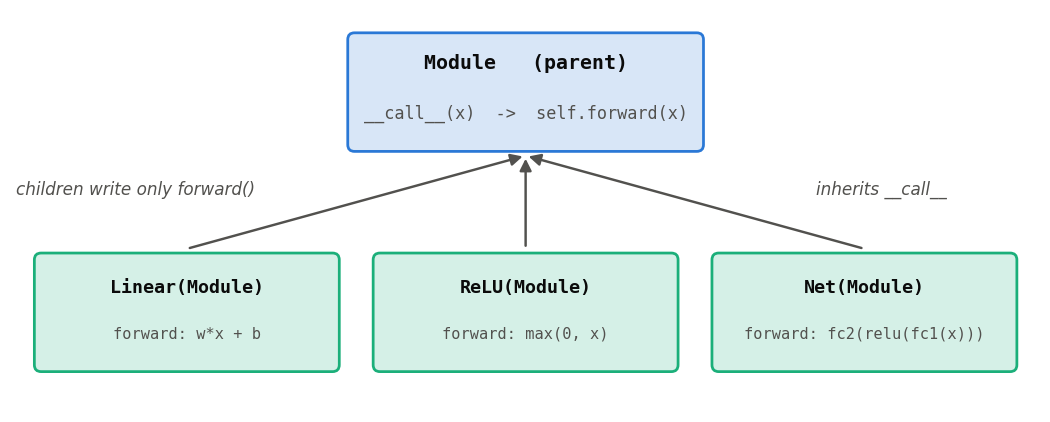

In [ ]:
class Module:
    """A toy version of torch.nn.Module."""

    def __init__(self):
        self.training = True             # the parent keeps some bookkeeping

    def __call__(self, x):               # model(x) -> model.forward(x)
        return self.forward(x)

    def forward(self, x):
        raise NotImplementedError("every child must define forward()")


class Linear(Module):
    def __init__(self, w, b):
        super().__init__()
        self.w, self.b = w, b

    def forward(self, x):
        return self.w * x + self.b


class ReLU(Module):
    def forward(self, x):
        return max(0.0, x)


class Net(Module):
    def __init__(self):
        super().__init__()               # run the parent's __init__ first
        self.fc1 = Linear(2.0, -1.0)
        self.act = ReLU()
        self.fc2 = Linear(-3.0, 0.5)

    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))


model = Net()
print(model(2.0))                        # Net has no __call__: it is inherited from Module
print(model.training)                    # set by Module.__init__ through super()

<div dir="rtl" style="direction: rtl; text-align: right;">

حالا اگر `super().__init__()` را فراموش کنیم چه می‌شود؟ `__init__` والد اجرا نمی‌شود و چیزهایی که والد باید می‌ساخت وجود ندارند:

</div>

In [ ]:
class BadNet(Module):
    def __init__(self):
        # super().__init__()   <- forgotten!
        self.fc = Linear(1.0, 0.0)

    def forward(self, x):
        return self.fc(x)

bad = BadNet()
try:
    print(bad.training)
except AttributeError as e:
    print("AttributeError:", e)

# In PyTorch the same mistake gives:
# AttributeError: cannot assign module before Module.__init__() call

<div dir="rtl" style="direction: rtl; text-align: right;">

**جمع‌بندی بخش ۸**

| کد PyTorch | چیزی که امروز یاد گرفتیم |
|---|---|
| `class Net(nn.Module):` | ارث‌بری |
| `super().__init__()` | اجرای `__init__` والد |
| `self.fc1 = nn.Linear(...)` | ذخیره‌ی حالت روی شیء با `self` |
| `def forward(self, x):` | متد |
| `model(x)` | `__call__` ارث‌برده که `forward` را صدا می‌زند |

</div>

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## بخش ۹ — ماژول و `import`

کدی که دیگران نوشته‌اند در **ماژول**ها و **پکیج**ها است. با `import` واردشان می‌کنیم:

| شکل | مثال | استفاده |
|---|---|---|
| `import X` | `import math` | `math.sqrt(2)` |
| `import X as Y` | `import numpy as np` | `np.zeros(3)` |
| `from X import Y` | `from math import pi` | `pi` |
| `from X import Y as Z` | `import torch.nn as nn` | `nn.Linear` |

اسم‌های کوتاه `np`، `plt`، `nn`، `F` قرارداد جامعه‌ی پایتون است؛ همه همین‌ها را استفاده می‌کنند.

نصب پکیج: در ترمینال `pip install numpy`، یا در نوت‌بوک `!pip install numpy`. (در Colab پکیج‌های اصلی از قبل نصب‌اند.)

</div>

In [ ]:
import math
import random
from collections import Counter

print(math.sqrt(2), math.pi, math.exp(1))

random.seed(0)                         # seed -> same "random" numbers every run
print(random.random(), random.choice(["cat", "dog"]))

print(Counter([3, 1, 3, 0, 1, 1, 2]))  # count of every label

<div dir="rtl" style="direction: rtl; text-align: right;">

---
## تمرین

1. **رشته:** لیست `names = ["conv1.weight", "conv1.bias", "fc.weight", "fc.bias"]` داده شده. با یک comprehension فقط اسم‌هایی را که با `weight` تمام می‌شوند جدا کنید.
2. **dict:** از لیست برچسب‌های `[3, 1, 3, 0, 1, 1, 2]` **بدون** `Counter`، یک dict بسازید که بگوید هر کلاس چند بار آمده.
3. **تابع:** تابع `conv_output_size` را طوری تغییر دهید که اگر خروجی کمتر از ۱ شد، با `raise ValueError` خطای مناسب بدهد.
4. **mutable:** تابعی بنویسید که یک لیست بگیرد و نسخه‌ی **نرمال‌شده**ی آن (هر عنصر تقسیم بر بزرگ‌ترین عنصر) را برگرداند، **بدون اینکه لیست اصلی تغییر کند**.
5. **کلاس:** کلاس `EarlyStopping(patience)` بنویسید با متد `step(val_loss)` که اگر loss به تعداد `patience` بار پشت سر هم بهتر نشد `True` برگرداند. با لیست `val_losses` بخش ۳ امتحانش کنید.
6. **ارث‌بری:** به Module اسباب‌بازی یک کلاس `Sigmoid` اضافه کنید ($\sigma(x) = \frac{1}{1 + e^{-x}}$، از `math.exp` استفاده کنید) و در `Net` به‌جای `ReLU` بگذارید.

**جلسه‌ی بعد:** چرا `a + b` روی آرایه‌ها کار می‌کند؟ (متدهای `__xxx__`)، generator و `DataLoader`، و بعد NumPy و Matplotlib.

</div>